
# Imam Abdulrahman Bin Faisal University
## ARTI 502 – Deep Learning
### Assignment 1: Training and Testing Neural Network with MNIST Dataset Using PyTorch

**Instructor:** Dr. Moatasem Alsmadi

**Group Number:** 4

**Group Members:**
1. Renad Salem Alqahtani – 2230004724
2. Jana Omar Alghamdi – 2230002367
3. Jood Yasser Alarfaj – 2230002692
4. Leen Mansour Alqahtani – 2230006599
5. [Student Name] – [Academic ID]
6. [Student Name] – [Academic ID]


##Task 1: Install PyTorch

In [1]:
%pip install torch

In [2]:
import torch

print("PyTorch version:", torch.__version__)
print("PyTorch installed successfully!")

PyTorch version: 2.11.0+cpu
PyTorch installed successfully!


##Task 2: Download and Load the Dataset


In [3]:
import torch
from torchvision import datasets, transforms

# Convert images to PyTorch tensors
transform = transforms.ToTensor()

# Download and load the MNIST dataset
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("MNIST dataset loaded successfully!")
print("Training dataset size:", len(train_dataset))
print("Testing dataset size:", len(test_dataset))

100%|██████████| 9.91M/9.91M [00:00<00:00, 133MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 17.4MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 108MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.56MB/s]


MNIST dataset loaded successfully!
Training dataset size: 60000
Testing dataset size: 10000


##Task 3: Inspect the Dataset

Batch of images shape: torch.Size([64, 1, 28, 28])
Batch of labels shape: torch.Size([64])


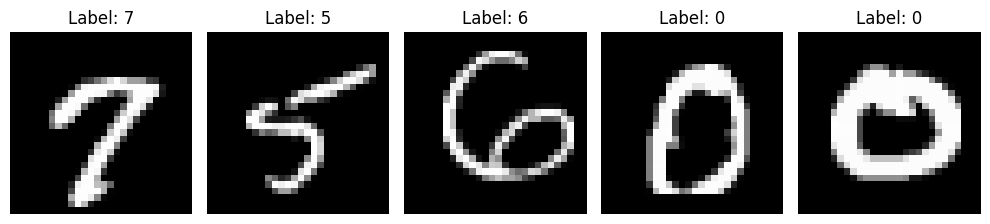

In [4]:
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

# Create a DataLoader to easily iterate through the dataset
train_loader = DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)

# Get one batch of training images and labels
data_iter = iter(train_loader)
images, labels = next(data_iter)

print("Batch of images shape:", images.shape)
print("Batch of labels shape:", labels.shape)

# Visualize some samples from the batch
fig, axes = plt.subplots(1, 5, figsize=(10, 3))
for i in range(5):
    # squeeze() removes the single-channel dimension
    axes[i].imshow(images[i].squeeze(), cmap='gray')
    axes[i].set_title(f"Label: {labels[i].item()}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

##Task 4: Creating A Simple Network

In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# Define a simple feedforward neural network
class SimpleNeuralNet(nn.Module):
    def __init__(self, input_size=784, hidden_size=128, num_classes=10):
        super(SimpleNeuralNet, self).__init__()
        # First fully connected layer
        self.fc1 = nn.Linear(input_size, hidden_size)
        # Second fully connected layer
        self.fc2 = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        # Flatten the image from (N, C, H, W) to (N, I) using torch.flatten
        # start_dim=1 ensures we keep the batch dimension intact
        x = torch.flatten(x, start_dim=1)
        # Apply activation function to the hidden layer
        x = F.relu(self.fc1(x))
        # Output layer
        x = self.fc2(x)
        return x

# Instantiate the model and print its architecture
model = SimpleNeuralNet()
print(model)

SimpleNeuralNet(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


##Task 5: Training Function

In [10]:
import torch
import torch.nn as nn
import torch.optim as optim

def train_network(net, train_loader, epochs=5, lr=0.01, momentum=0.9):
    """
    Trains the given neural network using cross-entropy loss and stochastic gradient descent.

    Parameters:
    - net: The PyTorch neural network model to train.
    - train_loader: DataLoader containing the training dataset.
    - epochs: Number of passes over the training dataset.
    - lr: Learning rate for the SGD optimizer.
    - momentum: Momentum for the SGD optimizer.
    """
    # 1. Define the loss function (Cross-Entropy Loss)
    criterion = nn.CrossEntropyLoss()

    # 2. Define the optimizer (Stochastic Gradient Descent with lr and momentum)
    optimizer = optim.SGD(net.parameters(), lr=lr, momentum=momentum)

    # Put the network in training mode
    net.train()

    # Store training losses and accuracies
    batch_losses = []
    epoch_losses = []
    epoch_accuracies = []

    print(f"Starting training for {epochs} epochs (Learning Rate: {lr}, Momentum: {momentum})...")

    for epoch in range(epochs):
        running_loss = 0.0
        correct_predictions = 0
        total_samples = 0

        for batch_idx, (images, labels) in enumerate(train_loader):
            # Zero the parameter gradients to prevent accumulation from previous batches
            optimizer.zero_grad()

            # Forward pass: compute predicted outputs by passing inputs to the model
            outputs = net(images)

            # Calculate the loss
            loss = criterion(outputs, labels)

            # Backward pass: compute gradient of the loss with respect to model parameters
            loss.backward()

            # Perform a single optimization step (parameter update)
            optimizer.step()

            # Store loss for each mini-batch
            batch_losses.append(loss.item())

            # Track training metrics
            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total_samples += labels.size(0)
            correct_predictions += (predicted == labels).sum().item()

            # Print training progress every 100 batches
            if (batch_idx + 1) % 100 == 0:
                batch_acc = (correct_predictions / total_samples) * 100
                print(f"Epoch [{epoch+1}/{epochs}] - Batch [{batch_idx+1}/{len(train_loader)}] - Loss: {loss.item():.4f} - Accuracy: {batch_acc:.2f}%")

        epoch_loss = running_loss / total_samples
        epoch_acc = (correct_predictions / total_samples) * 100

        # Store loss and accuracy for each epoch
        epoch_losses.append(epoch_loss)
        epoch_accuracies.append(epoch_acc)

        print(f"Epoch [{epoch+1}/{epochs}] - Loss: {epoch_loss:.4f} - Accuracy: {epoch_acc:.2f}%")

    print("Training completed successfully!")

    # Return training results for Task 6
    return batch_losses, epoch_losses, epoch_accuracies


##Task 6: Training Network

Starting training for 5 epochs (Learning Rate: 0.01, Momentum: 0.9)...
Epoch [1/5] - Batch [100/938] - Loss: 0.5654 - Accuracy: 64.16%
Epoch [1/5] - Batch [200/938] - Loss: 0.5554 - Accuracy: 74.84%
Epoch [1/5] - Batch [300/938] - Loss: 0.2390 - Accuracy: 79.41%
Epoch [1/5] - Batch [400/938] - Loss: 0.3196 - Accuracy: 81.89%
Epoch [1/5] - Batch [500/938] - Loss: 0.3798 - Accuracy: 83.47%
Epoch [1/5] - Batch [600/938] - Loss: 0.2511 - Accuracy: 84.56%
Epoch [1/5] - Batch [700/938] - Loss: 0.3305 - Accuracy: 85.47%
Epoch [1/5] - Batch [800/938] - Loss: 0.4286 - Accuracy: 86.25%
Epoch [1/5] - Batch [900/938] - Loss: 0.4176 - Accuracy: 86.87%
Epoch [1/5] - Loss: 0.4716 - Accuracy: 87.08%
Epoch [2/5] - Batch [100/938] - Loss: 0.4870 - Accuracy: 92.31%
Epoch [2/5] - Batch [200/938] - Loss: 0.2811 - Accuracy: 92.50%
Epoch [2/5] - Batch [300/938] - Loss: 0.1911 - Accuracy: 92.77%
Epoch [2/5] - Batch [400/938] - Loss: 0.1394 - Accuracy: 92.96%
Epoch [2/5] - Batch [500/938] - Loss: 0.1923 - Accu

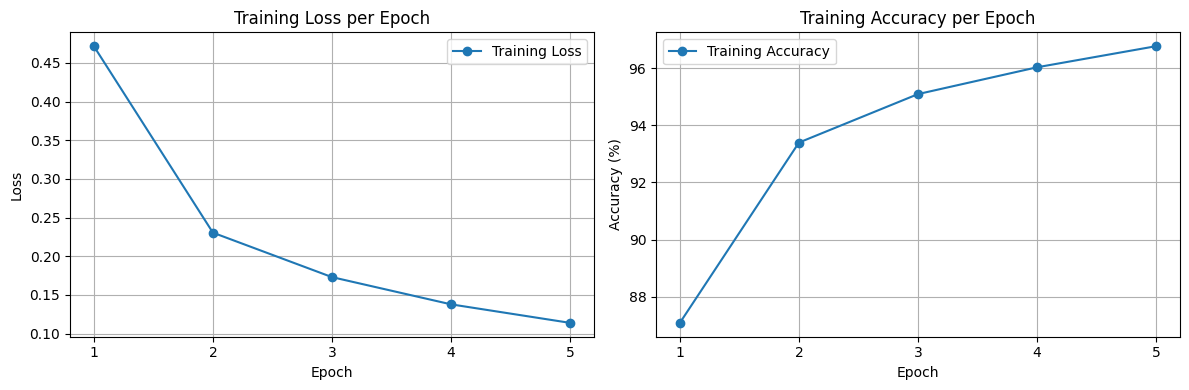

In [11]:
import matplotlib.pyplot as plt

# Create a new neural network
model = SimpleNeuralNet()

# Train the network using the training function from Task 5
batch_losses, epoch_losses, epoch_accuracies = train_network(
    model,
    train_loader,
    epochs=5,
    lr=0.01,
    momentum=0.9
)

# Plot training loss and accuracy for each epoch
epochs = range(1, len(epoch_losses) + 1)

plt.figure(figsize=(12, 4))

# Training Loss
plt.subplot(1, 2, 1)
plt.plot(epochs, epoch_losses, marker='o', label='Training Loss')
plt.title('Training Loss per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)

# Training Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs, epoch_accuracies, marker='o', label='Training Accuracy')
plt.title('Training Accuracy per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

##Task 7: Testing Network

##Task 8: Tuning the parameters and model archirecture